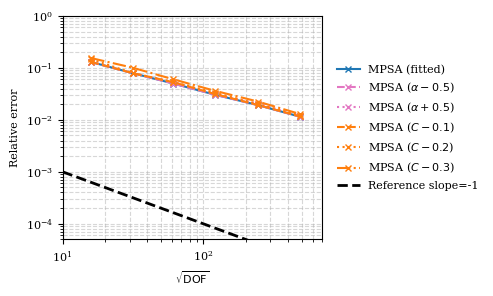

In [1]:
# Only for plot SIF results for all grid sizes
from __future__ import annotations
from dataclasses import dataclass

import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext

# MPSA
# From Fitting parameters: C=1.04, alpha=0.26
mpsa_dofs = np.array([
    16.00, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_mpsa = np.array([
    0.12930953, 0.07923498, 0.04995067, 0.03026051, 0.01923506, 0.01147821
])  
# From Fitting parameters: C=1.04, alpha=0.21
mpsa_dofs_2 = np.array([
    16.00, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_mpsa_2 = np.array([
    0.12930953, 0.07923498, 0.04995067, 0.03026051, 0.01923506, 0.01147821
]) 

# From Fitting parameters: C=1.04, alpha=0.31
mpsa_dofs_3 = np.array([
    16.00, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_mpsa_3 = np.array([
    0.12930953, 0.07923498, 0.05298672, 0.03121582, 0.02051244, 0.01206312
]) 

# From Fitting parameters: C=0.94, alpha=0.26
mpsa_dofs_4 = np.array([
    16.00, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_mpsa_4 = np.array([
    0.12930953, 0.07923498, 0.05298672, 0.03121582, 0.01930766, 0.01161009
]) 

# From Fitting parameters: C=0.84, alpha=0.26
mpsa_dofs_5 = np.array([
    16.00, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_mpsa_5 = np.array([
    0.14662601, 0.07923498, 0.05298672, 0.03310946, 0.01999905, 0.01206312
]) 
# From Fitting parameters: C=0.74, alpha=0.26
mpsa_dofs_6 = np.array([
    16.00, 31.43246729, 61.28621378, 122.01639234, 244.03688246, 487.59614437
])

err_ave_mpsa_6 = np.array([
    0.15405611, 0.10081094, 0.06015493, 0.03599161, 0.02250858, 0.01290347
]) 

# From Fitting parameters: C=0.64, alpha=0.25
# mpsa_dofs_7 = np.array([
#     16.32151574, 31.82437906, 62.97294016, 125.48940643, 250.10555251, 499.25663341
# ])

# err_ave_mpsa_7 = np.array([
#     0.1655984, 0.08088968, 0.05247497, 0.03260265, 0.02090855, 0.01260245
# ]) 

# From Fitting parameters: C=0.70, alpha=0.25
# mpsa_dofs_8 = np.array([
#     16.32151574, 31.82437906, 62.97294016, 125.48940643, 250.10555251, 499.25663341
# ])

# err_ave_mpsa_8 = np.array([
#     0.1655984, 0.09923475, 0.0591417, 0.03560988, 0.02281387, 0.013261
# ]) 

# Reference line
num_dofs_line = np.array([10, 30, 50, 70, 90, 100, 300, 500, 1000])
initial_value_line = 1e-3
first_order_line = initial_value_line * (num_dofs_line[0] / num_dofs_line)
half_order_line = initial_value_line  * (num_dofs_line[0] / num_dofs_line) ** 0.5

# Plot SIF KI
mpl.rcParams.update({
    "font.family": "serif",     
    "font.size": 8,             
    "axes.labelsize": 8,       
    "axes.titlesize": 8,        
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "lines.linewidth": 1.0,      
    "lines.markersize": 3.0,       
    "mathtext.fontset": "dejavusans",  
})
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))   # Scientific form

fig, ax = plt.subplots(figsize=(5.0, 3.0))   # inches
# MPSA
ax.loglog(
    mpsa_dofs,
    err_ave_mpsa,
    'x-',
    color='tab:blue',
    linewidth=1.5,
    markersize=4.0,
    label="MPSA (fitted)"
)
ax.loglog(
    mpsa_dofs_2,
    err_ave_mpsa_2,
    'x--',
    color='tab:pink',
    linewidth=1.5,
    markersize=4.0,
    label=rf"MPSA ($\alpha-0.5$)"
)
ax.loglog(
    mpsa_dofs_3,
    err_ave_mpsa_3,
    'x:',
    color='tab:pink',
    linewidth=1.5,
    markersize=4.0,
    label=rf"MPSA ($\alpha+0.5$)"
)
ax.loglog(
    mpsa_dofs_4,
    err_ave_mpsa_4,
    'x--',
    color='tab:orange',
    linewidth=1.5, 
    markersize=4.0,
    label=rf"MPSA ($C-0.1$)"
)

ax.loglog(
    mpsa_dofs_5,
    err_ave_mpsa_5,
    'x:',
    color='tab:orange',
    linewidth=1.5,
    markersize=4.0,
    label=rf"MPSA ($C-0.2$)"
)

ax.loglog(
    mpsa_dofs_6,
    err_ave_mpsa_6,
    'x-.',
    color='tab:orange',
    linewidth=1.5,
    markersize=4.0,
    label=rf"MPSA ($C-0.3$)"
)

# ax.loglog(
#     mpsa_dofs_7,
#     err_ave_mpsa_7,
#     'x-.',
#     color='tab:orange',
#     linewidth=1.5, 
#     markersize=4.0,
#     label="MPSA (C=0.80, alpha=0.25)"
# )

# ax.loglog(
#     mpsa_dofs_8,
#     err_ave_mpsa_8,
#     'x:',
#     color='tab:orange',
#     linewidth=1.5, 
#     markersize=4.0,
#     label="MPSA (C=0.70, alpha=0.25)"
# )

# QFEM
# ax.loglog(
#     fem_dofs,
#     err_ave_fem,
#     'x-',
#     color='tab:pink',
#     linewidth=2.0, 
#     markersize=4.0,
#     label="QFEM (ave)"
# )

ax.loglog(
    num_dofs_line, first_order_line,
    '--', color='k',
    linewidth=2.0,
    label="Reference slope=-1"
)

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.set_xlim(10, 700)
ax.set_ylim(0.00005, 1.0)
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.set_xlabel(r"$\sqrt{\mathrm{DOF}}$")
ax.set_ylabel("Relative error")

# ax.legend(loc="lower left")
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  
    frameon=False
)
ax.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
# plt.savefig("KI_convergence_so.tiff", format="tiff", dpi=300, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
# plt.savefig("sneddon_singularity.eps", format="eps", dpi=300, bbox_inches="tight")
plt.show()